In [291]:
from RK4_Erik.jax.RK4_jax import RK4
from Differential_equations.Jax import charge_particle_jax as cp_jax
from Differential_equations.Jax import Tokamak_jax as tok_jax

import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt
import time
from jax.experimental.ode import odeint

# 5A - Charged Particle, RK4

## 1

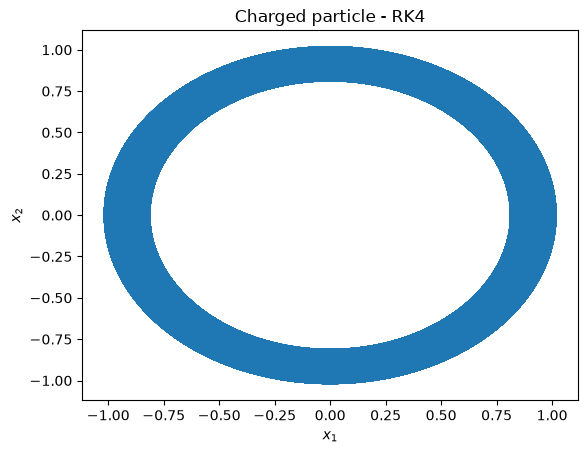

In [292]:
t = 0 #can be ignored
T = 10**5
Y0_cp = np.array([0, 1, 0.1, 0.09, 0.05, 0.20])
h = 0.1

CharPar_sol, times = RK4(t, T, Y0_cp, cp_jax.system, h)

X_cp = CharPar_sol[:3, :]
x1 = X_cp[0, :]
x2 = X_cp[1, :]

plt.plot(x1, x2)
plt.title("Charged particle - RK4")
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
plt.show()

comments

## 2

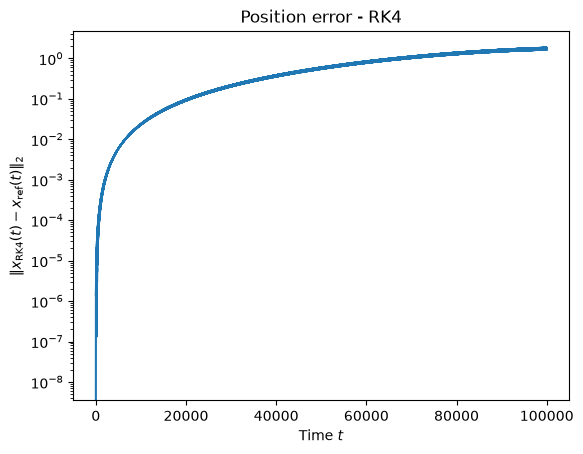

In [293]:
# odeint expects first Y then t
def reference_system(Y, t):
    return cp_jax.system(t, Y)

#gives refrence solution (jax version of solve_ivp, much faster)
Y_ref = odeint(
    reference_system,
    jnp.asarray(Y0_cp, dtype=jnp.float64),
    jnp.asarray(times, dtype=jnp.float64),
    rtol=1e-12,
    atol=1e-12,
)

X_ref_cp = np.asarray(Y_ref[:, :3]).T

norm_compare = np.linalg.norm(X_cp - X_ref_cp, axis=0)

plt.semilogy(times, norm_compare)
plt.title("Position error - RK4") 
plt.xlabel(r"Time $t$")
plt.ylabel(r"$\|x_{\mathrm{RK4}}(t)-x_{\mathrm{ref}}(t)\|_2$")
plt.show()

comment

## 3

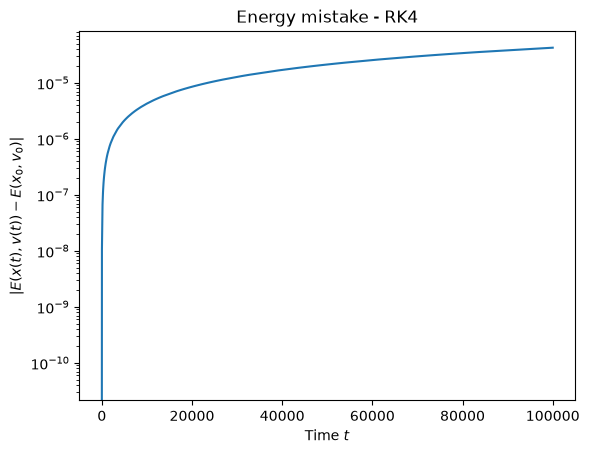

In [294]:
#energy convervation
V_cp = CharPar_sol[3:, :]
E = 0.5 * np.power(np.linalg.norm(V_cp, axis=0), 2) + cp_jax.U(X_cp)

e_n = np.abs(E - E[0])

plt.semilogy(times, e_n)
plt.title("Energy mistake - RK4")  
plt.xlabel(r"Time $t$")
plt.ylabel(r"$|E(x(t),v(t))-E(x_0,v_0)|$")
plt.show()

comments

# 5A - Tokamak, RK4

## 1

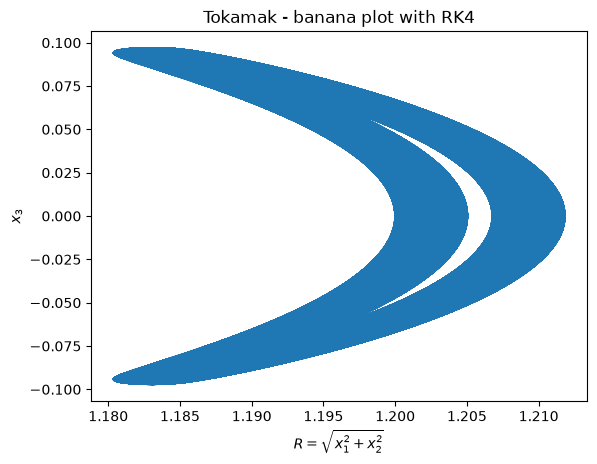

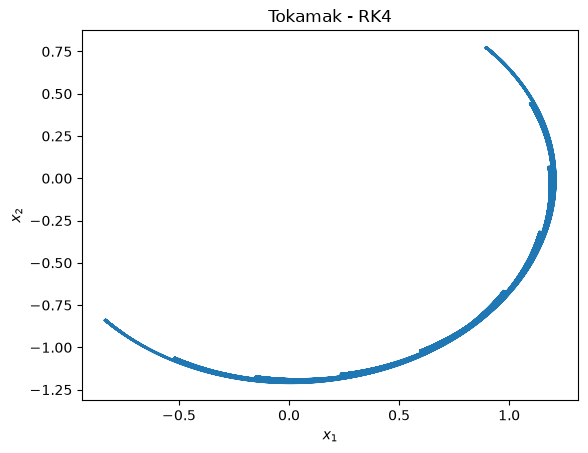

In [295]:
t = 0 #can be ignored
T = 10**5
Y0_tok = np.array([1.2, 0, 0, 0, 4.816*10**-4, -2.059*10**-3])
h = 0.1

tokamak_sol, times = RK4(t, T, Y0_tok, tok_jax.system, h)

x1x2 = tokamak_sol[:2, :]

R = np.linalg.norm(x1x2, axis=0)
x3 = tokamak_sol[2, :]

x1 = tokamak_sol[0, :]
x2 = tokamak_sol[1, :]

#R vs x3 plot
plt.plot(R, x3)
plt.title("Tokamak - banana plot with RK4")
plt.xlabel(r"$R = \sqrt{x_1^2 + x_2^2}$")
plt.ylabel(r"$x_3$")
plt.show()

#x1 vs x2 plot
plt.plot(x1, x2)
plt.title("Tokamak - RK4")
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
plt.show()


comments

## 2

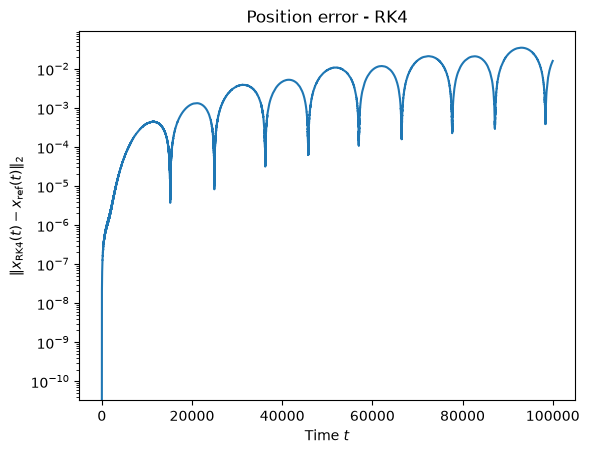

In [296]:
# odeint expects first Y then t
def reference_system(Y, t):
    return tok_jax.system(t, Y)

#gives refrence solution (jax version of solve_ivp, much faster)
Y_ref = odeint(
    reference_system,
    jnp.asarray(Y0_tok, dtype=jnp.float64),
    jnp.asarray(times, dtype=jnp.float64),
    rtol=1e-12,
    atol=1e-12,
)

X_tok = tokamak_sol[:3, :]

X_ref_tok = np.asarray(Y_ref[:, :3]).T

norm_compare = np.linalg.norm(X_tok - X_ref_tok, axis=0)

plt.semilogy(times, norm_compare)
plt.title("Position error - RK4") 
plt.xlabel(r"Time $t$")
plt.ylabel(r"$\|x_{\mathrm{RK4}}(t)-x_{\mathrm{ref}}(t)\|_2$")
plt.yscale("log")
plt.show()

comments

## 3

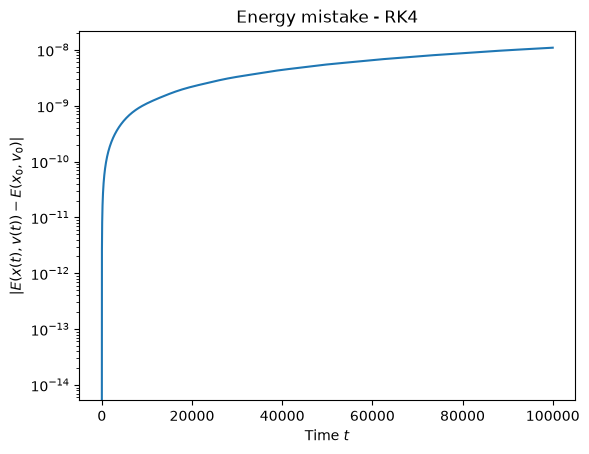

In [297]:
#energy convervation
V_tok = tokamak_sol[3:, :]
E = 0.5 * np.power(np.linalg.norm(V_tok, axis=0), 2) + tok_jax.U(X_tok)

e_n = np.abs(E - E[0])

plt.semilogy(times, e_n)
plt.title("Energy mistake - RK4")  # Legg gjerne til modellnavnet
plt.xlabel(r"Time $t$")
plt.ylabel(r"$|E(x(t),v(t))-E(x_0,v_0)|$")
plt.show()

comments

# 5B - charged particle, RK4

## 1

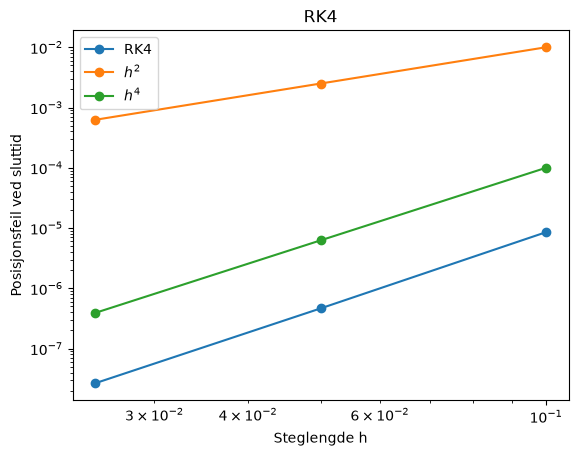

In [298]:
errors = np.zeros(3)
runtimes = np.zeros(3)
h_list = np.zeros(3)
T = 100
X_Ni_ref = X_ref_cp[:, 10*T]

for i in range(len(h_list)):
    hi = h/2**i
    h_list[i] = hi

    #RK4
    start = time.perf_counter()
    CharPar_sol_i, times_i = RK4(t, T, Y0_cp, cp_jax.system, hi)
    CharPar_sol_i.block_until_ready() 
    end = time.perf_counter()

    X_Ni_method = CharPar_sol_i[:3, -1]
    runtime = end - start

    errors[i] = np.linalg.norm(X_Ni_method - X_Ni_ref)
    runtimes[i] = runtime


ref_order2 = h_list**2
ref_order4 = h_list**4

plt.loglog(h_list, errors, "o-", label = "RK4")
plt.loglog(h_list, ref_order2, "o-", label=r"$h^2$")
plt.loglog(h_list, ref_order4, "o-", label=r"$h^4$")
plt.xlabel("Steglengde h")
plt.ylabel("Posisjonsfeil ved sluttid")
plt.title("RK4")
plt.legend()
plt.show()

comments

## 2

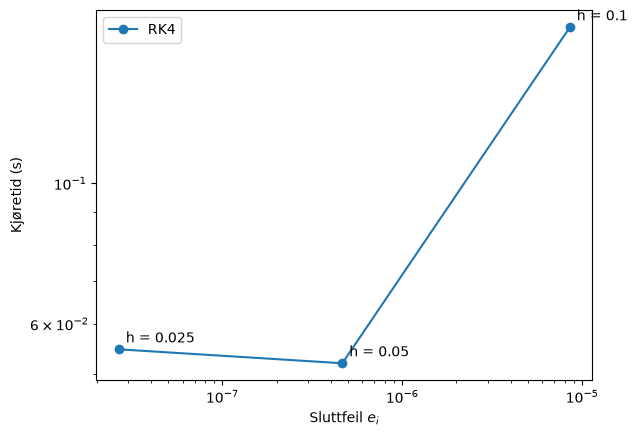

In [299]:
plt.loglog(errors, runtimes, "o-", label="RK4")

for i in range(len(errors)):
    plt.annotate(
        f"h = {h_list[i]:g}",
        (errors[i], runtimes[i]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel(r"Sluttfeil $e_i$")
plt.ylabel("Kjøretid (s)")
plt.legend()
plt.show()

comments

# 5B - Tokamak, RK4

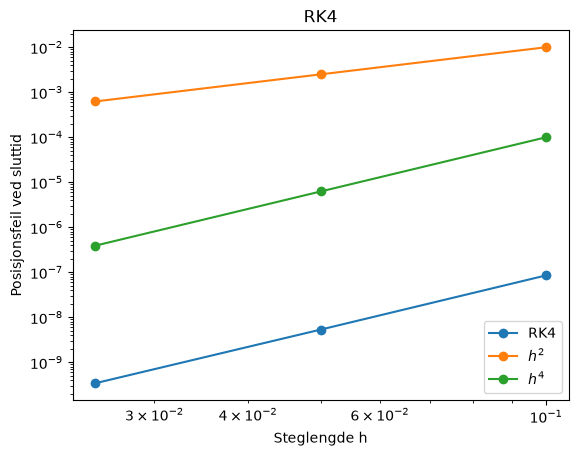

In [300]:
errors = np.zeros(3)
runtimes = np.zeros(3)
h_list = np.zeros(3)
T = 100
X_Ni_ref = X_ref_tok[:, 10*T]

for i in range(len(h_list)):
    hi = h/2**i
    h_list[i] = hi

    #RK4
    start = time.perf_counter()
    tokamak_sol_i, times_i = RK4(t, T, Y0_tok, tok_jax.system, hi)
    tokamak_sol_i.block_until_ready()
    end = time.perf_counter()

    X_Ni_method = tokamak_sol_i[:3, -1]
    runtime = end - start

    errors[i] = np.linalg.norm(X_Ni_method - X_Ni_ref)
    runtimes[i] = runtime


ref_order2 = h_list**2
ref_order4 = h_list**4

plt.loglog(h_list, errors, "o-", label = "RK4")
plt.loglog(h_list, ref_order2, "o-", label=r"$h^2$")
plt.loglog(h_list, ref_order4, "o-", label=r"$h^4$")
plt.xlabel("Steglengde h")
plt.ylabel("Posisjonsfeil ved sluttid")
plt.title("RK4")
plt.legend()
plt.show()

comments

## 2

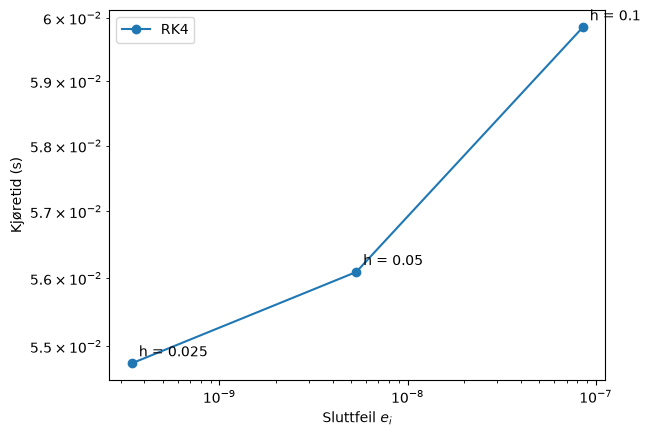

In [301]:
plt.loglog(errors, runtimes, "o-", label="RK4")

for i in range(len(errors)):
    plt.annotate(
        f"h = {h_list[i]:g}",
        (errors[i], runtimes[i]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel(r"Sluttfeil $e_i$")
plt.ylabel("Kjøretid (s)")
plt.legend()
plt.show()